In [1]:
%pip install -q landingai pillow matplotlib gTTS

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
blobfile 3.3.0 requires urllib3>=2, but you have urllib3 1.26.20 which is incompatible.
spacy 3.8.18

In [2]:
%pip install landingai

In [2]:
import io
import re
import numpy as np

from PIL import Image
from google.colab import files, userdata
from IPython.display import display, Markdown, Audio

from landingai.predict import Predictor, OcrPredictor
from landingai.visualize import overlay_bboxes
from gtts import gTTS

In [9]:
from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

ENDPOINT_ID = "YOUR_MEDICINE_ENDPOINT_ID"

detector = Predictor(
    endpoint_id="7648ecd9-24f9-4b14-80ab-837f678adc01",
    api_key=API_KEY
)

print("Medicine Label Detection Model Connected!")

Medicine Label Detection Model Connected!


In [10]:
from landingai.predict import OcrPredictor

ocr = OcrPredictor(
    api_key=API_KEY,
    language="en"
)

print("OCR Engine Connected!")

OCR Engine Connected!


Saving screenshot-2026-11-12-221010.png to screenshot-2026-11-12-221010 (1).png
Image uploaded successfully!
Image dimensions: (462, 536)


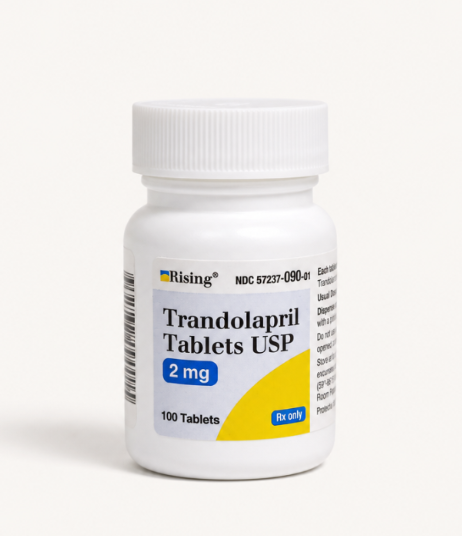

In [11]:
uploaded = files.upload()

filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as img:
    image = img.convert("RGB").copy()

image_array = np.array(image)

print("Image uploaded successfully!")
print("Image dimensions:", image.size)

display(image)

In [12]:
predictions = detector.predict(image_array)

print("Detection Results:")

for prediction in predictions:
    print("Label:", prediction.label_name)
    print("Confidence:", prediction.score)
    print("Bounding Box:", prediction.bboxes)

Detection Results:
Label: Medicine_Label
Confidence: 0.9470216035842896
Bounding Box: (152, 272, 313, 416)


In [13]:
# Reading text
ocr_predictions = ocr.predict(image_array)

extracted_text = []

print("Extracted Medicine Label Text:\n")

for item in ocr_predictions:
    print(item.text)
    extracted_text.append(item.text)

full_text = "\n".join(extracted_text)

print("\nComplete Extracted Text:")
print(full_text)

Extracted Medicine Label Text:

"Risingo
100 Tablets
2mg
Ax only
DANE
NDC 57237-090-01
Tablets USP
Trandolapril

Complete Extracted Text:
"Risingo
100 Tablets
2mg
Ax only
DANE
NDC 57237-090-01
Tablets USP
Trandolapril


In [14]:
import re

def extract_medicine_information(text):

    lines = [line.strip() for line in text.split("\n") if line.strip()]

    information = {
        "Medicine Name": "Not identified",
        "Strength": "Not identified",
        "Expiry Date": "Not identified",
        "Manufacturing Date": "Not identified",
        "Batch Number": "Not identified"
    }

    for line in lines:

        upper = line.upper()

        # Extract medicine strength
        strength = re.search(
            r'\b\d+(?:\.\d+)?\s*(?:MG|MCG|G|ML|IU)\b', upper
        )

        if strength and information["Strength"] == "Not identified":
            information["Strength"] = strength.group()

        # Extract expiry date
        expiry = re.search(
            r'(?:EXP|EXPIRY|EXPIRES)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4}|\d{2}[/-]\d{2,4})',
            upper
        )

        if expiry:
            information["Expiry Date"] = expiry.group(1)

        # Extract manufacturing date
        manufacturing = re.search(
            r'(?:MFG|MFD|MANUFACTURED)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4}|\d{2}[/-]\d{2,4})',
            upper
        )

        if manufacturing:
            information["Manufacturing Date"] = manufacturing.group(1)

        # Extract batch number
        batch = re.search(
            r'(?:BATCH|B\.?NO\.?|LOT)\s*[:\-]?\s*([A-Z0-9-]+)',
            upper
        )

        if batch:
            information["Batch Number"] = batch.group(1)

    if lines:
        information["Medicine Name"] = lines[0]

    return information


medicine_info = extract_medicine_information(full_text)

for key, value in medicine_info.items():
    print(f"{key}: {value}")

Medicine Name: "Risingo
Strength: 2MG
Expiry Date: Not identified
Manufacturing Date: Not identified
Batch Number: Not identified


In [15]:
def medicine_assistant_response(info):

    response = f"""
# MEDICINE LABEL READING ASSISTANT

**Medicine Name:** {info['Medicine Name']}

**Strength:** {info['Strength']}

**Expiry Date:** {info['Expiry Date']}

**Manufacturing Date:** {info['Manufacturing Date']}

**Batch Number:** {info['Batch Number']}

---
Please verify all extracted information against the original medicine packaging.

This assistant reads medicine labels only.
It does not provide dosage recommendations or determine medication safety.
"""

    display(Markdown(response))

    return response


assistant_response = medicine_assistant_response(medicine_info)


# MEDICINE LABEL READING ASSISTANT

**Medicine Name:** "Risingo

**Strength:** 2MG

**Expiry Date:** Not identified

**Manufacturing Date:** Not identified

**Batch Number:** Not identified

---
Please verify all extracted information against the original medicine packaging.

This assistant reads medicine labels only.
It does not provide dosage recommendations or determine medication safety.


In [16]:
speech = gTTS(text=assistant_response, lang="en")

speech.save("medicine_assistant.mp3")

display(Audio("medicine_assistant.mp3", autoplay=False))

In [17]:
import ipywidgets as widgets
from IPython.display import display, clear_output

upload_button = widgets.FileUpload(
    accept='image/*',
    multiple=False,
    description='Upload Medicine'
)

output = widgets.Output()

def process_medicine(change):
    with output:
        clear_output()

        if not upload_button.value:
            print("Please upload a medicine image.")
            return

        uploaded_file = list(upload_button.value.values())[0]
        image_bytes = uploaded_file['content']

        img = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        img_array = np.array(img)

        display(img)

        # Detecting the medicine label
        predictions = detector.predict(img_array)

        # Extracting text using OCR
        ocr_predictions = ocr.predict(img_array)

        full_text = "\n".join(
            item.text for item in ocr_predictions
        )

        # Extracting medicine information
        info = extract_medicine_information(full_text)

        # Displaying the results
        display(Markdown("## Medicine Information"))

        for key, value in info.items():
            print(f"{key}: {value}")

        # Voice output
        response = medicine_assistant_response(info)

        speech = gTTS(text=response, lang="en")
        speech.save("medicine_assistant.mp3")

        display(Audio("medicine_assistant.mp3", autoplay=False))

upload_button.observe(process_medicine, names='value')

display(Markdown("# Medicine Label Reading Assistant"))
display(Markdown("Upload a medicine bottle image to extract its information."))
display(upload_button, output)

# Medicine Label Reading Assistant

Upload a medicine bottle image to extract its information.

FileUpload(value={}, accept='image/*', description='Upload Medicine')

Output()